# Post-LoRA Style × Answer-Code Crossover Audit

下一步：先排除画风和答案字母混杂，再决定是否继续做 L50 因果机制验证。

[实验设置与运行说明](../../../docs/experiment_notes/07_appendix_lora_training/d023832c6e8cf022.md)


In [1]:
# Run once. Every later code cell reports progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 14 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 14 tracked cells.


## 1. 冻结设计、检查原实验并生成完全交叉输入


In [2]:
%%cell_progress 1/14 Mount Drive and select a complete VisualTorque project
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Auditing candidate project roots')
from pathlib import Path
import shutil

PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
REQUIRED_TOOLKIT_PATHS = (
    'pyproject.toml',
    'src/visual_torque_toolkit/__init__.py',
    'src/visual_torque_toolkit/contracts.py',
    'src/visual_torque_toolkit/classify.py',
    'src/visual_torque_toolkit/dataset.py',
    'src/visual_torque_toolkit/edits.py',
    'src/visual_torque_toolkit/generate.py',
    'src/visual_torque_toolkit/prompts.py',
    'src/visual_torque_toolkit/render.py',
    'src/visual_torque_toolkit/splits.py',
    'src/visual_torque_toolkit/world.py',
    'src/visual_torque_toolkit/behavior/__init__.py',
    'src/visual_torque_toolkit/behavior/adapter.py',
    'src/visual_torque_toolkit/behavior/data.py',
    'src/visual_torque_toolkit/behavior/schema.py',
)

def missing_toolkit_paths(project_root):
    toolkit_root = project_root / 'toolkit'
    return [
        relative for relative in REQUIRED_TOOLKIT_PATHS
        if not (toolkit_root / relative).is_file()
    ]

candidate_audit = {
    str(candidate): missing_toolkit_paths(candidate)
    for candidate in PROJECT_CANDIDATES
}
complete_candidates = [
    candidate for candidate in PROJECT_CANDIDATES
    if not candidate_audit[str(candidate)]
]
assert complete_candidates, (
    'No complete VisualTorque toolkit was found. '
    f'Missing-file audit: {candidate_audit}'
)
PROJECT_ROOT = complete_candidates[0]

cell_stage('Copying immutable toolkit source to local SSD')
DRIVE_TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
TOOLKIT_ROOT = Path('/content/visualtorque_style_code_runtime')
import tempfile
TOOLKIT_ROOT = Path(tempfile.mkdtemp(prefix='visualtorque_style_code_', dir='/content'))
shutil.copytree(DRIVE_TOOLKIT_ROOT, TOOLKIT_ROOT, dirs_exist_ok=True)
print('Project:', PROJECT_ROOT)
print('Toolkit runtime:', TOOLKIT_ROOT)


Mount Drive and select a complete VisualTorque project:   0%|          | 0/14 [00:00<?, ?cell/s]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/VisualTorque
Toolkit runtime: /content/visualtorque_style_code_jcvy8ejw


In [3]:
%%cell_progress 2/14 Install and verify the frozen inference environment
import importlib
import importlib.metadata
import json
import os
import subprocess
import sys

cell_stage('Configuring caches before importing Torch')
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
os.environ.setdefault('HF_HOME', '/content/hf_cache')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

cell_stage('Removing incompatible optional Torch packages')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio', 'torchao'],
    check=False,
)
importlib.invalidate_caches()

cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    '--upgrade-strategy', 'only-if-needed',
    'transformers==5.14.0', 'peft==0.20.0', 'accelerate>=1.10',
    'sentencepiece', 'protobuf', 'huggingface_hub>=0.34',
    'safetensors', 'tqdm>=4.66', 'scikit-learn>=1.5',
    'scipy>=1.13', 'pandas>=2.2', 'matplotlib>=3.8',
    'joblib>=1.4', 'pillow>=10.4',
])

cell_stage('Importing the immutable toolkit copy')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if module_name == 'visual_torque_toolkit' or module_name.startswith('visual_torque_toolkit.'):
        del sys.modules[module_name]
importlib.invalidate_caches()

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import visual_torque_toolkit
from IPython.display import display
from peft import PeftModel
from scipy.stats import binomtest
from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter
from visual_torque_toolkit.generate import (
    GenerationConfig, generate_multi_stack_scenes,
)
from visual_torque_toolkit.prompts import QuestionKind, generate_questions
from visual_torque_toolkit.render import RenderStyle, render_scene

# Defensive Qwen3.5 compatibility patch for exact candidate scoring.
def append_text_prefix_aligned(self, inputs, prefix):
    if not prefix:
        return inputs
    batch_size = inputs['input_ids'].shape[0]
    prefix_tensor = torch.tensor(
        prefix,
        dtype=inputs['input_ids'].dtype,
        device=inputs['input_ids'].device,
    ).unsqueeze(0).expand(batch_size, -1)
    inputs['input_ids'] = torch.cat((inputs['input_ids'], prefix_tensor), dim=1)
    attention_extension = torch.ones(
        (batch_size, len(prefix)),
        dtype=inputs['attention_mask'].dtype,
        device=inputs['attention_mask'].device,
    )
    inputs['attention_mask'] = torch.cat(
        (inputs['attention_mask'], attention_extension), dim=1
    )
    for key in ('token_type_ids', 'mm_token_type_ids'):
        if key not in inputs:
            continue
        extension = torch.zeros(
            (batch_size, len(prefix)),
            dtype=inputs[key].dtype,
            device=inputs[key].device,
        )
        inputs[key] = torch.cat((inputs[key], extension), dim=1)
    inputs.pop('position_ids', None)
    return inputs

HuggingFaceMultimodalAdapter._append_text_prefix = append_text_prefix_aligned
torch.backends.cuda.matmul.allow_tf32 = True
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents
try:
    torchao_version = importlib.metadata.version('torchao')
except importlib.metadata.PackageNotFoundError:
    torchao_version = None
assert torchao_version is None
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('transformers:', importlib.metadata.version('transformers'))
print('peft:', importlib.metadata.version('peft'))
print('Toolkit:', toolkit_path)


Install and verify the frozen inference environment:   7%|7         | 1/14 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
transformers: 5.14.0
peft: 0.20.0
Toolkit: /content/visualtorque_style_code_jcvy8ejw/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/14 Freeze configuration and verify the adapter
cell_stage('Freezing the diagnostic scope')
import copy
import hashlib
import itertools
import math
from collections import Counter, defaultdict
from contextlib import contextmanager
from dataclasses import asdict
from datetime import datetime, timezone
from PIL import Image
from visual_torque_toolkit.world import Scene, Side, Stack

IMPLEMENTATION_SHA256 = 'sha256:dfe15661fa455e6e32ee156337c810d1c537bca6d947d412c92532febafaa862'
MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
SEED = 20260916
RUN_VERSION = 'v1'
BOOTSTRAP_REPLICATES = 10000
PARITY_TOLERANCE = 0.03
MODES = ('native', 'lora')
TASKS = ('outcome', 'torque_relation')
ALPHABETS = {'ABC': ('A', 'B', 'C'), 'XYZ': ('X', 'Y', 'Z')}
ORIGINAL_ALPHABET = {'outcome': 'ABC', 'torque_relation': 'XYZ'}
SEMANTICS = ('left', 'balanced', 'right')
STYLES = {
    'blue_shift': RenderStyle(width=1440, height=640, ticks_per_side=12,
        beam_y=404, block_size=28, block_gap=3, background=(246,247,242),
        ink=(40,47,42), block_fill=(49,117,161)),
    'coral_shift': RenderStyle(width=1536, height=672, ticks_per_side=12,
        beam_y=424, block_size=30, block_gap=2, background=(249,243,241),
        ink=(49,41,43), block_fill=(180,82,74)),
}
TRAIN_ROOT = PROJECT_ROOT / 'results/qwen27b_bf16_lora_weight_shortcut_v1'
ADAPTER_DIR = TRAIN_ROOT / 'adapter_final'
ADAPTER_MANIFEST_PATH = TRAIN_ROOT / 'ADAPTER_MANIFEST.json'
PRIOR_ROOT = PROJECT_ROOT / 'results/qwen27b_postlora_l50_metric_route_blind_causal_v1'
PRIOR_DATASET = PRIOR_ROOT / 'blind_metric_route_dataset'
OUTPUT_ROOT = PROJECT_ROOT / 'results' / f'qwen27b_postlora_style_code_crossover_{RUN_VERSION}'
DATASET_DIR = OUTPUT_ROOT / 'crossed_dataset'
PREDICTION_DIR = OUTPUT_ROOT / 'predictions'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for directory in (DATASET_DIR, PREDICTION_DIR, ANALYSIS_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
assert OUTPUT_ROOT.resolve() != PRIOR_ROOT.resolve()

def json_default(value):
    if isinstance(value, Path): return str(value)
    if isinstance(value, np.generic): return value.item()
    raise TypeError(type(value).__name__)

def canonical_json(value):
    return json.dumps(value, sort_keys=True, ensure_ascii=False, default=json_default, allow_nan=False)

def digest_object(value):
    return 'sha256:' + hashlib.sha256(canonical_json(value).encode()).hexdigest()

def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(canonical_json(value) + '\n', encoding='utf-8')
    temporary.replace(path)

def write_jsonl(path, records):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(''.join(canonical_json(row) + '\n' for row in records), encoding='utf-8')
    temporary.replace(path)

def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text(encoding='utf-8').splitlines() if line.strip()]

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''): digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def hash_tree(directory):
    return {path.relative_to(directory).as_posix(): sha256_file(path)
            for path in sorted(Path(directory).rglob('*')) if path.is_file()}

def freeze_json(path, identity):
    identity = json.loads(canonical_json(identity))
    path = Path(path)
    if path.exists():
        existing = json.loads(path.read_text(encoding='utf-8'))
        assert existing['identity'] == identity, (
            f'Frozen input changed: {path}. Do not mix results; use a new RUN_VERSION.'
        )
    else:
        write_json(path, {'identity': identity, 'locked_at_utc': datetime.now(timezone.utc).isoformat()})
    return digest_object(identity)

assert torch.cuda.is_available(), 'Select the same 96 GB GPU runtime as the preceding experiment.'
assert torch.cuda.get_device_properties(0).total_memory / 2**30 >= 88
assert importlib.metadata.version('transformers') == '5.14.0'
assert importlib.metadata.version('peft') == '0.20.0'
adapter_manifest = json.loads(ADAPTER_MANIFEST_PATH.read_text(encoding='utf-8'))
assert adapter_manifest['base_model_id'] == MODEL_ID
assert adapter_manifest['base_model_revision'] == MODEL_REVISION
assert hash_tree(ADAPTER_DIR) == adapter_manifest['adapter_files']
print('Adapter verified; all original result files remain read-only.')
print('Output:', OUTPUT_ROOT)


Freeze configuration and verify the adapter:  14%|#4        | 2/14 [00:00<?, ?cell/s]

Adapter verified; all original result files remain read-only.
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_style_code_crossover_v1


In [5]:
%%cell_progress 4/14 Audit prior scenes and freeze source evidence
cell_stage('Reading the completed experiment, without selecting on predictions')
SOURCE_PATHS = {
    'complete': PRIOR_ROOT / 'RUN_COMPLETE.json',
    'protocol': PRIOR_ROOT / 'frozen_protocol.json',
    'dataset_lock': PRIOR_ROOT / 'dataset_lock.json',
    'manifest_lock': PRIOR_ROOT / 'confirmatory_manifest_lock.json',
    'scene_manifest': PRIOR_ROOT / 'scene_manifest.jsonl',
    'pairs': PRIOR_ROOT / 'ordinal_flip_pairs.jsonl',
    'selected_prompts': PRIOR_ROOT / 'confirmatory_manifest.jsonl',
    'scenes': PRIOR_DATASET / 'scenes.jsonl',
    'questions': PRIOR_DATASET / 'questions.jsonl',
    'prior_predictions': PRIOR_ROOT / 'analysis/clean_prompt_predictions.jsonl',
}
for path in SOURCE_PATHS.values(): assert path.is_file(), f'Missing previous output: {path}'
prior_dataset_identity = json.loads(SOURCE_PATHS['dataset_lock'].read_text())['identity']
for name, expected in prior_dataset_identity['dataset_hashes'].items():
    assert sha256_file(PRIOR_DATASET / name) == expected, name
assert sha256_file(SOURCE_PATHS['scene_manifest']) == prior_dataset_identity['scene_manifest_sha256']
assert sha256_file(SOURCE_PATHS['pairs']) == prior_dataset_identity['pair_manifest_sha256']
prior_manifest_identity = json.loads(SOURCE_PATHS['manifest_lock'].read_text())['identity']
assert sha256_file(SOURCE_PATHS['selected_prompts']) == prior_manifest_identity['manifest_sha256']
prior_meta = read_jsonl(SOURCE_PATHS['scene_manifest'])
prior_scenes = read_jsonl(SOURCE_PATHS['scenes'])
prior_questions = read_jsonl(SOURCE_PATHS['questions'])
prior_manifest = read_jsonl(SOURCE_PATHS['selected_prompts'])
prior_pairs = read_jsonl(SOURCE_PATHS['pairs'])
prior_predictions = read_jsonl(SOURCE_PATHS['prior_predictions'])
prior_meta_by_id = {row['scene_id']: row for row in prior_meta}
prior_scene_by_id = {row['scene_id']: row for row in prior_scenes}
prior_question_by_id = {row['question_id']: row for row in prior_questions}
assert len(prior_meta_by_id) == len(prior_scene_by_id) == 44
assert set(prior_meta_by_id) == set(prior_scene_by_id)
assert Counter(row['stratum'] for row in prior_meta) == {'ordinal_flip':24, 'near_boundary':12, 'exact_balance':8}
assert len(prior_pairs) == 12 and len(prior_manifest) == 264
assert len({row['example_id'] for row in prior_manifest}) == 264
assert len(prior_predictions) == 528

def scene_from_record(record, scene_id=None):
    return Scene(scene_id or record['scene_id'], tuple(
        Stack(stack['stack_id'], Side(stack['side']), int(stack['distance']), int(stack['units']))
        for stack in record['stacks']))

source_image_hashes = {}
for sid, record in prior_scene_by_id.items():
    scene = scene_from_record(record)
    meta = prior_meta_by_id[sid]
    # Independent arithmetic, in addition to the toolkit oracle.
    left = sum(int(s['units']) * int(s['distance']) for s in record['stacks'] if s['side'] == 'left')
    right = sum(int(s['units']) * int(s['distance']) for s in record['stacks'] if s['side'] == 'right')
    expected_outcome = 'left' if left > right else 'right' if left < right else 'balanced'
    assert scene.net_torque == left - right == record['derived']['net_torque'] == meta['net_torque']
    assert scene.outcome.value == expected_outcome == meta['outcome'] == record['derived']['outcome']
    assert meta['style'] in STYLES and len(scene.stacks) == 2
    source_image_hashes[sid] = sha256_file(PRIOR_DATASET / record['image_path'])

# Build connected components: shared pair OR mirrored geometry implies dependence.
parent = {sid: sid for sid in prior_meta_by_id}
def find(sid):
    while parent[sid] != sid:
        parent[sid] = parent[parent[sid]]
        sid = parent[sid]
    return sid
def union(a, b):
    ra, rb = find(a), find(b)
    parent[max(ra, rb)] = min(ra, rb)
mirror_groups = defaultdict(list)
for sid, record in prior_scene_by_id.items():
    signature = scene_from_record(record).canonical_signature
    mirror = tuple(sorted(('right' if side == 'left' else 'left', distance, units)
                          for side, distance, units in signature))
    mirror_groups[min(signature, mirror)].append(sid)
for members in mirror_groups.values():
    for sid in members[1:]: union(members[0], sid)
paired_ids = []
for pair in prior_pairs:
    a, b = pair['weight_wins_scene_id'], pair['distance_wins_scene_id']
    ma, mb = prior_meta_by_id[a], prior_meta_by_id[b]
    assert ma['pair_id'] == mb['pair_id'] == pair['pair_id']
    assert ma['pair_member'] == 'weight_wins' and mb['pair_member'] == 'distance_wins'
    assert ma['outcome'] != mb['outcome']
    assert ma['weight_relation'] == mb['weight_relation']
    assert ma['distance_relation'] == mb['distance_relation']
    union(a, b)
    paired_ids.extend([a, b])
assert len(set(paired_ids)) == 24
family_by_scene = {sid: 'family_' + hashlib.sha256(find(sid).encode()).hexdigest()[:16] for sid in parent}
primary_families = {family_by_scene[sid] for sid in paired_ids}

source_crosstab = pd.crosstab(pd.Series([r['pair_member'] for r in prior_meta if r['primary']], name='member'),
                             pd.Series([r['style'] for r in prior_meta if r['primary']], name='original_style'))
source_crosstab.to_csv(ANALYSIS_DIR / 'prior_member_style_crosstab.csv')
display(source_crosstab)
print('Independent connected families:', len(set(family_by_scene.values())),
      '| primary:', len(primary_families), '| physical pairs:', len(prior_pairs))
protocol = {
    'version':'style-code-crossover-1.0', 'implementation_sha256':IMPLEMENTATION_SHA256,
    'model_id':MODEL_ID, 'revision':MODEL_REVISION, 'dtype':MODEL_DTYPE,
    'adapter_manifest_sha256':sha256_file(ADAPTER_MANIFEST_PATH),
    'source_hashes':{key:sha256_file(path) for key,path in SOURCE_PATHS.items()},
    'source_image_hashes':source_image_hashes,
    'toolkit_source_hashes':hash_tree(TOOLKIT_ROOT / 'src/visual_torque_toolkit'),
    'styles':{key:asdict(value) for key,value in STYLES.items()},
    'alphabets':ALPHABETS, 'tasks':TASKS, 'seed':SEED,
    'scene_count':44, 'input_count':1056, 'model_scores':2112,
    'primary_scope':'24 seen ordinal-flip scenes, outcome, ABC; original three mappings, both styles',
    'planned_contrasts':[
        'crossed_lora_minus_native_accuracy',
        'lora_original_minus_swapped_accuracy',
        'lora_minus_native_style_probability_sensitivity'],
    'multiplicity':'Holm adjustment for the three planned two-sided sign-flip tests',
    'uncertainty':'family cluster bootstrap, equal geometry weights; sign flips at connected-family level',
    'pair_ties':'no unique mode => tie; both-correct and valid-flip are false; ties reported separately',
    'bootstrap_replicates':BOOTSTRAP_REPLICATES,
    'status':'post-hoc controlled follow-up; not a new blind confirmation',
}
# Exclude import-generated bytecode from reproducibility fingerprints.
protocol['toolkit_source_hashes'] = {k:v for k,v in protocol['toolkit_source_hashes'].items() if k.endswith('.py') or k.endswith('.json')}
PROTOCOL_PATH = OUTPUT_ROOT / 'frozen_protocol.json'
PROTOCOL_ID = freeze_json(PROTOCOL_PATH, protocol)
write_json(ANALYSIS_DIR / 'independent_families.json', family_by_scene)


Audit prior scenes and freeze source evidence:  21%|##1       | 3/14 [00:00<?, ?cell/s]

original_style,blue_shift,coral_shift
member,,
distance_wins,0,12
weight_wins,12,0


Independent connected families: 21 | primary: 6 | physical pairs: 12


In [6]:
%%cell_progress 5/14 Render every geometry in both original styles
cell_stage('Crossing each physical scene with both styles')
new_scenes, new_questions, crossed_scene_rows = [], [], []
question_provenance = {}
prior_selected_by_scene_task = defaultdict(list)
for item in prior_manifest:
    prior_selected_by_scene_task[(item['scene_id'], item['question_kind'])].append(item)
assert len(prior_selected_by_scene_task) == 88
pixel_audit = []
for sid in tqdm(sorted(prior_meta_by_id), desc='Crossed geometry rendering', unit='scene'):
    original = prior_scene_by_id[sid]
    meta = prior_meta_by_id[sid]
    for style_name, style in STYLES.items():
        new_sid = f'{sid}__render_{style_name}'
        scene = scene_from_record(original, new_sid)
        image_relative = Path('images') / style_name / f'{sid}.png'
        image_path = DATASET_DIR / image_relative
        render_scene(scene, image_path, style)
        if style_name == meta['style']:
            with Image.open(PRIOR_DATASET / original['image_path']) as a, Image.open(image_path) as b:
                same_pixels = a.size == b.size and a.convert('RGB').tobytes() == b.convert('RGB').tobytes()
            pixel_audit.append({'source_scene_id':sid, 'same_pixels':same_pixels})
            assert same_pixels, (
                f'Original-style render differs for {sid}. Check toolkit renderer/Pillow before running models.'
            )
        record = scene.to_record()
        record.update(split='style_code_crossover', image_path=image_relative.as_posix())
        record['metadata'] = {'source_scene_id':sid, 'style':style_name,
            'original_style':meta['style'], 'family_id':family_by_scene[sid]}
        new_scenes.append(record)
        crossed_scene_rows.append({
            'scene_id':new_sid, 'source_scene_id':sid, 'style':style_name,
            'original_style':meta['style'], 'family_id':family_by_scene[sid],
            'stratum':meta['stratum'], 'pair_id':meta['pair_id'],
            'pair_member':meta['pair_member'], 'gold_semantic':meta['outcome'],
            'weight_relation':meta['weight_relation'], 'distance_relation':meta['distance_relation'],
            'net_torque':meta['net_torque'], 'primary':bool(meta['primary']),
        })
        for task in TASKS:
            selected_rows = sorted(prior_selected_by_scene_task[(sid,task)], key=lambda r:r['variant'])
            assert len(selected_rows) == 3
            for alphabet, labels in ALPHABETS.items():
                for item in selected_rows:
                    question = copy.deepcopy(prior_question_by_id[item['question_id']])
                    assert question['semantic_answer'] == meta['outcome']
                    question_id = f"{item['question_id']}__render_{style_name}__code_{alphabet}"
                    question.update(question_id=question_id, scene_id=new_sid, split='style_code_crossover')
                    for label, option in zip(labels, question['options']): option['label'] = label
                    question['correct_label'] = next(o['label'] for o in question['options'] if o['semantic'] == meta['outcome'])
                    new_questions.append(question)
                    question_provenance[question_id] = {
                        'source_scene_id':sid, 'source_example_id':item['example_id'],
                        'source_question_id':item['question_id'], 'alphabet':alphabet,
                        'original_alphabet':ORIGINAL_ALPHABET[task],
                    }
assert len(new_scenes) == 88 and len(new_questions) == 1056
write_jsonl(DATASET_DIR / 'scenes.jsonl', new_scenes)
write_jsonl(DATASET_DIR / 'questions.jsonl', new_questions)
write_jsonl(DATASET_DIR / 'counterfactual_pairs.jsonl', [])
write_json(DATASET_DIR / 'splits.json', {'style_code_crossover':[r['scene_id'] for r in new_scenes]})
write_json(DATASET_DIR / 'statistics.json', {'scenes':88,'physical_geometries':44,'questions':1056})
write_json(DATASET_DIR / 'dataset_config.json', {'schema_version':'style-code-crossover-1.0', 'protocol_id':PROTOCOL_ID})
write_jsonl(OUTPUT_ROOT / 'crossed_scene_manifest.jsonl', crossed_scene_rows)
write_json(ANALYSIS_DIR / 'original_pixel_parity.json', pixel_audit)
selection_by_scene = {row['scene_id']:row for row in crossed_scene_rows}
print('All 44 original-style images reproduced exactly; 88 crossed images ready.')


Render every geometry in both original styles:  29%|##8       | 4/14 [00:00<?, ?cell/s]

Crossed geometry rendering:   0%|          | 0/44 [00:00<?, ?scene/s]

All 44 original-style images reproduced exactly; 88 crossed images ready.


In [7]:
%%cell_progress 6/14 Freeze the crossed prompt inventory
cell_stage('Preserving the previous semantic mappings within each geometry and task')
config = BehaviorRunConfig(dataset_dir=DATASET_DIR, output_dir=OUTPUT_ROOT / '_unused',
    model_id=MODEL_ID, model_revision=MODEL_REVISION, conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=TASKS, splits=('style_code_crossover',), batch_size=1, seed=SEED)
test_examples = list(load_behavior_examples(config))
test_examples.sort(key=lambda ex:hashlib.sha256(f'{SEED}:{ex.example_id}'.encode()).hexdigest())
assert len(test_examples) == 1056
assert len({ex.example_id for ex in test_examples}) == 1056
example_metadata = {}
for example in test_examples:
    scene_meta = selection_by_scene[example.scene_id]
    provenance = question_provenance[example.question_id]
    row = {**scene_meta, **provenance, 'example_id':example.example_id,
           'question_kind':example.question_kind, 'variant':example.variant,
           'gold_label':example.gold_label, 'gold_semantic':str(example.gold_semantic)}
    row['input_sha256'] = digest_object({'prompt':example.prompt,
        'image_sha256':sha256_file(example.image_path),
        'labels':example.labels, 'semantics':example.option_semantics, 'metadata':row})
    example_metadata[example.example_id] = row
write_jsonl(OUTPUT_ROOT / 'crossed_prompt_manifest.jsonl', list(example_metadata.values()))
manifest_frame = pd.DataFrame(example_metadata.values())
display(manifest_frame.groupby(['stratum','question_kind','alphabet','style']).size().unstack('style'))


Freeze the crossed prompt inventory:  36%|###5      | 5/14 [00:00<?, ?cell/s]

style                                   blue_shift  coral_shift
stratum       question_kind   alphabet                         
exact_balance outcome         ABC               24           24
                              XYZ               24           24
              torque_relation ABC               24           24
                              XYZ               24           24
near_boundary outcome         ABC               36           36
                              XYZ               36           36
              torque_relation ABC               36           36
                              XYZ               36           36
ordinal_flip  outcome         ABC               72           72
                              XYZ               72           72
              torque_relation ABC               72           72
                              XYZ               72           72

In [8]:
%%cell_progress 7/14 Verify the full design before any model forward
cell_stage('Checking mappings, physical pairing, and independent families')
for keys, group in manifest_frame.groupby(['source_scene_id','question_kind','alphabet','style']):
    assert len(group) == 3 and set(group['gold_label']) == set(ALPHABETS[keys[2]])
for keys, group in manifest_frame.groupby(['source_scene_id','question_kind','variant']):
    assert len(group) == 4
    assert set(zip(group['style'],group['alphabet'])) == set(itertools.product(STYLES,ALPHABETS))
by_key = {(ex.scene_id,ex.question_kind,ex.variant,question_provenance[ex.question_id]['alphabet']):ex
          for ex in test_examples}
for sid in prior_meta_by_id:
    for task in TASKS:
        for selected_row in prior_selected_by_scene_task[(sid,task)]:
            variants = [by_key[(f'{sid}__render_{style}',task,selected_row['variant'],alphabet)]
                        for style in STYLES for alphabet in ALPHABETS]
            assert len({ex.option_semantics for ex in variants}) == 1
            for alphabet in ALPHABETS:
                a,b = [by_key[(f'{sid}__render_{style}',task,selected_row['variant'],alphabet)] for style in STYLES]
                assert a.prompt == b.prompt

# Exact original prompt reproduction includes textual options, not just labels.
old_config = BehaviorRunConfig(dataset_dir=PRIOR_DATASET, output_dir=OUTPUT_ROOT / '_unused_prior',
    model_id=MODEL_ID, conditions=(PromptCondition.IMAGE_RULE,), question_kinds=TASKS,
    splits=('blind_metric_route',), batch_size=1)
old_examples = {ex.example_id:ex for ex in load_behavior_examples(old_config)}
reproduced = 0
for ex in test_examples:
    meta = example_metadata[ex.example_id]
    if meta['style'] == meta['original_style'] and meta['alphabet'] == meta['original_alphabet']:
        previous = old_examples[meta['source_example_id']]
        assert ex.prompt == previous.prompt
        assert ex.labels == previous.labels and ex.option_semantics == previous.option_semantics
        reproduced += 1
assert reproduced == 264

DATA_FILES = ('scenes.jsonl','questions.jsonl','counterfactual_pairs.jsonl','splits.json','statistics.json','dataset_config.json')
data_identity = {'protocol_id':PROTOCOL_ID,
    'dataset_hashes':{name:sha256_file(DATASET_DIR/name) for name in DATA_FILES},
    'image_hashes':{r['image_path']:sha256_file(DATASET_DIR/r['image_path']) for r in new_scenes},
    'manifest_sha256':sha256_file(OUTPUT_ROOT/'crossed_prompt_manifest.jsonl'),
    'scene_manifest_sha256':sha256_file(OUTPUT_ROOT/'crossed_scene_manifest.jsonl')}
DATA_LOCK_PATH = OUTPUT_ROOT / 'dataset_lock.json'
DATA_ID = freeze_json(DATA_LOCK_PATH, data_identity)
RUN_ID = digest_object({'protocol':PROTOCOL_ID,'data':DATA_ID})
freeze_json(PREDICTION_DIR/'identity.json', {'run_id':RUN_ID,'examples':1056,'models':MODES})
print('Design passed; 264 original prompts reproduced exactly.')
print('1,056 unique inputs × 2 model states = 2,112 main scores.')
print('Primary independent families:', len(primary_families))
if len(primary_families) < 10:
    print('Small family count: wide intervals and coarse exact p-values are expected. Null results are inconclusive.')


Verify the full design before any model forward:  43%|####2     | 6/14 [00:00<?, ?cell/s]

Design passed; 264 original prompts reproduced exactly.
1,056 unique inputs × 2 model states = 2,112 main scores.
Primary independent families: 6
Small family count: wide intervals and coarse exact p-values are expected. Null results are inconclusive.


## 2. 固定 adapter，逐输入运行并断点续跑


In [9]:
%%cell_progress 8/14 Load the pinned BF16 base and frozen LoRA
cell_stage('Rechecking frozen inputs before loading the model')
for key,path in SOURCE_PATHS.items(): assert sha256_file(path) == protocol['source_hashes'][key]
for sid,record in prior_scene_by_id.items():
    assert sha256_file(PRIOR_DATASET/record['image_path']) == source_image_hashes[sid]
for name,expected in data_identity['dataset_hashes'].items(): assert sha256_file(DATASET_DIR/name) == expected
for name,expected in data_identity['image_hashes'].items(): assert sha256_file(DATASET_DIR/name) == expected
assert hash_tree(ADAPTER_DIR) == adapter_manifest['adapter_files']
cell_stage('Loading the same pinned checkpoint as the preceding experiment')
adapter = HuggingFaceMultimodalAdapter(MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map='cuda:0')
assert not hasattr(adapter.model,'peft_config')
adapter.model = PeftModel.from_pretrained(adapter.model, str(ADAPTER_DIR), is_trainable=False)
adapter.model.eval()
for parameter in adapter.model.parameters(): parameter.requires_grad_(False)
assert not any(p.requires_grad for p in adapter.model.parameters())
runtime = {'model_id':MODEL_ID,'revision':MODEL_REVISION,'dtype':MODEL_DTYPE,
    'torch':torch.__version__,'transformers':importlib.metadata.version('transformers'),
    'peft':importlib.metadata.version('peft'),'pillow':importlib.metadata.version('pillow'),
    'cuda':torch.version.cuda,'gpu':torch.cuda.get_device_name(0)}
freeze_json(OUTPUT_ROOT/'runtime_lock.json', runtime)
print('Frozen model ready; no training or activation patches will run.')


Load the pinned BF16 base and frozen LoRA:  50%|#####     | 7/14 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

Frozen model ready; no training or activation patches will run.


In [10]:
%%cell_progress 9/14 Define exact scoring and check both answer alphabets
cell_stage('Checking exact single-token candidates')
@contextmanager
def model_mode(mode):
    if mode == 'native':
        with adapter.model.disable_adapter(): yield
    elif mode == 'lora': yield
    else: raise ValueError(mode)

def score_one(example, mode):
    plan = adapter._candidate_plan(example)
    assert plan is not None, 'A legal label is not an exact single-token candidate.'
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(adapter._to_device(adapter._template(
        [example.messages()], add_generation_prompt=True)), fixed_prefix)
    mask = inputs['attention_mask'].bool()
    position = (mask.long() * torch.arange(mask.shape[1],device=mask.device).unsqueeze(0)).max(dim=1).values
    with model_mode(mode), torch.inference_mode():
        output = adapter.model(**inputs, use_cache=False)
    logprobs = torch.log_softmax(output.logits[0,position[0],:].float(),dim=-1)
    scores = {str(example.label_to_semantic[label]):float(logprobs[token_by_label[label]].cpu()) for label in example.labels}
    assert set(scores) == set(SEMANTICS) and all(math.isfinite(v) for v in scores.values())
    # Preserve the original option-order tie convention for raw model predictions.
    prediction = max(scores,key=scores.get)
    gold = str(example.gold_semantic)
    vector = np.array([scores[key] for key in SEMANTICS],dtype=float)
    probabilities = np.exp(vector-vector.max()); probabilities /= probabilities.sum()
    meta = example_metadata[example.example_id]
    result = {**meta,'model':mode,'semantic_logprobs':scores,
        'semantic_probabilities':dict(zip(SEMANTICS,probabilities.tolist())),
        'predicted_semantic':prediction,'correct':prediction==gold,
        'correct_margin':scores[gold]-max(v for k,v in scores.items() if k!=gold),
        'weight_follow':prediction==meta['weight_relation'],
        'distance_follow':prediction==meta['distance_relation'],
        'balanced_prediction':prediction=='balanced'}
    del inputs,output,logprobs
    return result

def prediction_path(example,mode):
    return PREDICTION_DIR / f"{mode}_{hashlib.sha256(example.example_id.encode()).hexdigest()[:24]}.json"

def validate_shard(payload,example,mode):
    assert payload['run_id'] == RUN_ID
    record = payload['record']
    assert record['example_id'] == example.example_id and record['model'] == mode
    assert record['input_sha256'] == example_metadata[example.example_id]['input_sha256']
    assert set(record['semantic_logprobs']) == set(SEMANTICS)
    assert all(math.isfinite(v) for v in record['semantic_logprobs'].values())
    return record

prior_lookup = {(r['model'],r['example_id']):r for r in prior_predictions}
assert len(prior_lookup) == 528
smoke_rows = []
for task in TASKS:
    for alphabet in ALPHABETS:
        ex = next(ex for ex in test_examples if ex.question_kind==task
            and example_metadata[ex.example_id]['alphabet']==alphabet
            and example_metadata[ex.example_id]['style']==example_metadata[ex.example_id]['original_style'])
        for mode in MODES:
            record = score_one(ex,mode)
            with model_mode(mode),torch.inference_mode():
                reference = adapter.score_batch([ex])[0].logprob_by_label
            ours = np.array([record['semantic_logprobs'][str(ex.label_to_semantic[label])] for label in ex.labels])
            theirs = np.array([reference[label] for label in ex.labels])
            error = float(np.max(np.abs((ours-ours.mean())-(theirs-theirs.mean()))))
            assert error < PARITY_TOLERANCE, ('candidate scorer mismatch',task,alphabet,mode,error)
            smoke_rows.append({'task':task,'alphabet':alphabet,'model':mode,'centered_score_error':error})
write_json(ANALYSIS_DIR/'candidate_scoring_parity.json',smoke_rows)
display(pd.DataFrame(smoke_rows))

def run_mode(mode):
    created = reused = 0
    for ex in tqdm(test_examples,desc=f'{mode}: crossed style × task × code',unit='input'):
        path = prediction_path(ex,mode)
        if path.exists():
            validate_shard(json.loads(path.read_text(encoding='utf-8')),ex,mode)
            reused += 1
        else:
            record = score_one(ex,mode)
            payload = {'run_id':RUN_ID,'record':record}
            validate_shard(payload,ex,mode)
            write_json(path,payload)
            created += 1
    print(mode, '| new:',created,'| resumed:',reused,'| complete:',created+reused)


Define exact scoring and check both answer alphabets:  57%|#####7    | 8/14 [00:00<?, ?cell/s]

,task,alphabet,model,centered_score_error
0,outcome,ABC,native,0.0
1,outcome,ABC,lora,0.0
2,outcome,XYZ,native,0.0
3,outcome,XYZ,lora,0.0
4,torque_relation,ABC,native,0.0
5,torque_relation,ABC,lora,0.0
6,torque_relation,XYZ,native,0.0
7,torque_relation,XYZ,lora,0.0


In [11]:
%%cell_progress 10/14 Score or resume Native on every crossed input
cell_stage('Scoring the frozen base model')
run_mode('native')


Score or resume Native on every crossed input:  64%|######4   | 9/14 [00:00<?, ?cell/s]

native: crossed style × task × code:   0%|          | 0/1056 [00:00<?, ?input/s]

native | new: 1056 | resumed: 0 | complete: 1056


In [12]:
%%cell_progress 11/14 Score or resume LoRA on identical crossed inputs
cell_stage('Scoring the unchanged trained adapter')
run_mode('lora')


Score or resume LoRA on identical crossed inputs:  71%|#######1  | 10/14 [00:00<?, ?cell/s]

lora: crossed style × task × code:   0%|          | 0/1056 [00:00<?, ?input/s]

lora | new: 1056 | resumed: 0 | complete: 1056


## 3. 先检查复现，再解释画风、字母和正确性


In [13]:
%%cell_progress 12/14 Aggregate scene, pair, style and answer-code behavior
cell_stage('Loading and validating all completed predictions')
prediction_rows = [validate_shard(json.loads(prediction_path(ex,mode).read_text(encoding='utf-8')),ex,mode)
                   for mode in MODES for ex in test_examples]
assert len(prediction_rows) == 2112
write_jsonl(ANALYSIS_DIR/'all_prompt_predictions.jsonl',prediction_rows)
frame = pd.DataFrame(prediction_rows)

def unique_mode(values):
    counts = Counter(values)
    winners = [key for key,count in counts.items() if count==max(counts.values())]
    return winners[0] if len(winners)==1 else 'tie'

def legacy_mode(values):
    counts = Counter(values)
    return sorted(counts,key=lambda key:(-counts[key],key))[0]

scene_rows = []
for keys,group in frame.groupby(['model','source_scene_id','question_kind','alphabet','style'],sort=True):
    mode,sid,task,alphabet,style = keys
    assert len(group)==3
    meta = prior_meta_by_id[sid]
    scene_rows.append({'model':mode,'source_scene_id':sid,'question_kind':task,'alphabet':alphabet,'style':style,
        'original_style':meta['style'],'family_id':family_by_scene[sid],
        'stratum':meta['stratum'],'pair_id':meta['pair_id'],'pair_member':meta['pair_member'],
        'gold_semantic':meta['outcome'],'accuracy':float(group['correct'].mean()),
        'correct_margin':float(group['correct_margin'].mean()),
        'weight_follow_rate':float(group['weight_follow'].mean()),
        'distance_follow_rate':float(group['distance_follow'].mean()),
        'balanced_prediction_rate':float(group['balanced_prediction'].mean()),
        'modal_prediction':unique_mode(group['predicted_semantic']),
        'legacy_modal_prediction':legacy_mode(group['predicted_semantic']),
        'mapping_unanimous':group['predicted_semantic'].nunique()==1,
        'all_mappings_correct':bool(group['correct'].all())})
scene_frame = pd.DataFrame(scene_rows)
scene_frame['modal_tie'] = scene_frame['modal_prediction']=='tie'
scene_frame.to_csv(ANALYSIS_DIR/'scene_behavior.csv',index=False)
summary = scene_frame.groupby(['model','question_kind','alphabet','stratum','style'],as_index=False).agg(
    geometries=('source_scene_id','size'),accuracy=('accuracy','mean'),correct_margin=('correct_margin','mean'),
    weight_follow_rate=('weight_follow_rate','mean'),distance_follow_rate=('distance_follow_rate','mean'),
    balanced_prediction_rate=('balanced_prediction_rate','mean'),mapping_unanimous=('mapping_unanimous','mean'),
    modal_tie_rate=('modal_tie','mean'))
summary.to_csv(ANALYSIS_DIR/'behavior_summary.csv',index=False)

# Pair success under common styles and under old/swapped style assignments.
scene_lookup = {(r['model'],r['source_scene_id'],r['question_kind'],r['alphabet'],r['style']):r for r in scene_rows}
pair_rows = []
for mode,task,alphabet in itertools.product(MODES,TASKS,ALPHABETS):
    for pair in prior_pairs:
        ids = [pair['weight_wins_scene_id'],pair['distance_wins_scene_id']]
        for assignment in ('original','swapped','all_blue','all_coral'):
            selected = []
            for sid in ids:
                original_style = prior_meta_by_id[sid]['style']
                style = original_style if assignment=='original' else next(s for s in STYLES if s!=original_style) if assignment=='swapped' else 'blue_shift' if assignment=='all_blue' else 'coral_shift'
                selected.append(scene_lookup[(mode,sid,task,alphabet,style)])
            predictions = [r['modal_prediction'] for r in selected]
            valid = 'tie' not in predictions
            legacy = [r['legacy_modal_prediction'] for r in selected]
            pair_rows.append({'model':mode,'question_kind':task,'alphabet':alphabet,'assignment':assignment,
                'pair_id':pair['pair_id'],'family_id':family_by_scene[ids[0]],
                'pair_accuracy':float(np.mean([r['accuracy'] for r in selected])),
                'both_modal_correct':bool(valid and all(r['modal_prediction']==r['gold_semantic'] for r in selected)),
                'both_all_mappings_correct':all(r['all_mappings_correct'] for r in selected),
                'valid_modal_flip':bool(valid and predictions[0]!=predictions[1]),
                'any_modal_tie':not valid,
                'legacy_both_modal_correct':all(r['legacy_modal_prediction']==r['gold_semantic'] for r in selected),
                'legacy_modal_flip':legacy[0]!=legacy[1]})
pair_frame = pd.DataFrame(pair_rows)
pair_frame.to_csv(ANALYSIS_DIR/'pair_behavior.csv',index=False)
pair_summary = pair_frame.groupby(['model','question_kind','alphabet','assignment'],as_index=False).agg(
    pairs=('pair_id','size'),pair_accuracy=('pair_accuracy','mean'),both_modal_correct=('both_modal_correct','mean'),
    both_all_mappings_correct=('both_all_mappings_correct','mean'),valid_modal_flip=('valid_modal_flip','mean'),
    any_modal_tie=('any_modal_tie','mean'),legacy_both_modal_correct=('legacy_both_modal_correct','mean'))
pair_summary.to_csv(ANALYSIS_DIR/'pair_summary.csv',index=False)

def probability_tv(first,second):
    return 0.5*sum(abs(first['semantic_probabilities'][s]-second['semantic_probabilities'][s]) for s in SEMANTICS)

row_lookup = {(r['model'],r['source_scene_id'],r['question_kind'],r['alphabet'],r['style'],r['variant']):r for r in prediction_rows}
sensitivity_rows = []
for mode,sid,task in itertools.product(MODES,sorted(prior_meta_by_id),TASKS):
    meta = prior_meta_by_id[sid]
    for item in prior_selected_by_scene_task[(sid,task)]:
        variant = item['variant']
        for alphabet in ALPHABETS:
            a,b = [row_lookup[(mode,sid,task,alphabet,style,variant)] for style in STYLES]
            sensitivity_rows.append({'model':mode,'source_scene_id':sid,'family_id':family_by_scene[sid],
                'stratum':meta['stratum'],'question_kind':task,'dimension':'style','held_condition':alphabet,
                'variant':variant,'prediction_changed':a['predicted_semantic']!=b['predicted_semantic'],
                'probability_tv':probability_tv(a,b),'absolute_margin_change':abs(a['correct_margin']-b['correct_margin'])})
        for style in STYLES:
            a,b = [row_lookup[(mode,sid,task,alphabet,style,variant)] for alphabet in ALPHABETS]
            sensitivity_rows.append({'model':mode,'source_scene_id':sid,'family_id':family_by_scene[sid],
                'stratum':meta['stratum'],'question_kind':task,'dimension':'alphabet','held_condition':style,
                'variant':variant,'prediction_changed':a['predicted_semantic']!=b['predicted_semantic'],
                'probability_tv':probability_tv(a,b),'absolute_margin_change':abs(a['correct_margin']-b['correct_margin'])})
sensitivity_frame = pd.DataFrame(sensitivity_rows)
sensitivity_scene = sensitivity_frame.groupby(['model','source_scene_id','family_id','stratum','question_kind','dimension','held_condition'],as_index=False).agg(
    prediction_change_rate=('prediction_changed','mean'),probability_tv=('probability_tv','mean'),
    absolute_margin_change=('absolute_margin_change','mean'))
sensitivity_scene.to_csv(ANALYSIS_DIR/'style_and_alphabet_sensitivity.csv',index=False)

# Technical reproduction: original images, original alphabets, identical mappings.
parity_rows = []
for row in prediction_rows:
    if row['style']!=row['original_style'] or row['alphabet']!=row['original_alphabet']: continue
    previous = prior_lookup[(row['model'],row['source_example_id'])]
    current = np.array([row['semantic_logprobs'][s] for s in SEMANTICS])
    old_scores = np.array([previous['semantic_logprobs'][s] for s in SEMANTICS])
    parity_rows.append({'model':row['model'],'question_kind':row['question_kind'],
        'source_example_id':row['source_example_id'],'source_scene_id':row['source_scene_id'],
        'centered_logprob_error':float(np.max(np.abs((current-current.mean())-(old_scores-old_scores.mean())))),
        'prediction_matches':row['predicted_semantic']==previous['predicted_semantic']})
assert len(parity_rows)==528
parity_frame = pd.DataFrame(parity_rows)
parity_frame.to_csv(ANALYSIS_DIR/'prior_prediction_parity.csv',index=False)
display(parity_frame.groupby(['model','question_kind']).agg(max_score_error=('centered_logprob_error','max'),prediction_match_rate=('prediction_matches','mean')))
display(pair_summary[(pair_summary['question_kind']=='outcome') & (pair_summary['alphabet']=='ABC')].round(4))


Aggregate scene, pair, style and answer-code behavior:  79%|#######8  | 11/14 [00:00<?, ?cell/s]

max_score_error  prediction_match_rate
model  question_kind                                          
lora   outcome             6.279599e-11                    1.0
       torque_relation     6.357048e-11                    1.0
native outcome             6.357026e-11                    1.0
       torque_relation     6.511836e-11                    1.0

,model,question_kind,alphabet,assignment,pairs,pair_accuracy,both_modal_correct,both_all_mappings_correct,valid_modal_flip,any_modal_tie,legacy_both_modal_correct
0,lora,outcome,ABC,all_blue,12,0.5000,0.0833,0.0833,0.5833,0.0833,0.0833
1,lora,outcome,ABC,all_coral,12,0.5139,0.1667,0.0000,0.7500,0.0000,0.1667
2,lora,outcome,ABC,original,12,0.4722,0.0833,0.0833,0.6667,0.0833,0.0833
3,lora,outcome,ABC,swapped,12,0.5417,0.1667,0.0833,0.6667,0.0000,0.1667
16,native,outcome,ABC,all_blue,12,0.5139,0.0000,0.0000,0.0000,0.0000,0.0000
17,native,outcome,ABC,all_coral,12,0.5139,0.0000,0.0000,0.0833,0.0000,0.0000
18,native,outcome,ABC,original,12,0.4861,0.0000,0.0000,0.0833,0.0000,0.0000
19,native,outcome,ABC,swapped,12,0.5417,0.0000,0.0000,0.0000,0.0000,0.0000


In [14]:
%%cell_progress 13/14 Estimate controlled contrasts with family-level uncertainty
cell_stage('Resampling independent families, not prompts or rendered images')
def cluster_summary(rows, value, seed, signed_test=False):
    values = rows[['family_id',value]].copy()
    assert len(values)>0 and np.isfinite(values[value].to_numpy(dtype=float)).all()
    clusters = values.groupby('family_id')[value].agg(['sum','count'])
    sums = clusters['sum'].to_numpy(dtype=float); counts = clusters['count'].to_numpy(dtype=float)
    n = len(clusters); estimate = float(sums.sum()/counts.sum())
    result = {'n_units':len(values),'n_families':n,'mean':estimate,
              'ci_low':None,'ci_high':None,'p_value':None,'test':None}
    if n<2: return result
    rng = np.random.default_rng(seed)
    indices = rng.integers(0,n,size=(BOOTSTRAP_REPLICATES,n))
    bootstrap = sums[indices].sum(axis=1)/counts[indices].sum(axis=1)
    low,high = np.quantile(bootstrap,[0.025,0.975])
    result.update(ci_low=float(low),ci_high=float(high))
    if signed_test:
        if n<=16:
            signs = np.array(list(itertools.product((-1.,1.),repeat=n)))
            null = signs@sums/counts.sum()
            p = np.mean(np.abs(null)>=abs(estimate)-1e-12)
            test = 'exact_two_sided_family_sign_flip'
        else:
            signs = rng.choice((-1.,1.),size=(10000,n))
            null = signs@sums/counts.sum()
            p = (1+np.sum(np.abs(null)>=abs(estimate)-1e-12))/(len(null)+1)
            test = 'monte_carlo_two_sided_family_sign_flip'
        result.update(p_value=float(p),test=test)
    return result

def holm_adjust(p_values):
    order = np.argsort(p_values)
    adjusted = [0.]*len(p_values); previous = 0.
    for rank,index in enumerate(order):
        previous = max(previous,min(1.,(len(p_values)-rank)*float(p_values[index])))
        adjusted[index] = previous
    return adjusted

primary = scene_frame[(scene_frame['stratum']=='ordinal_flip') &
                      (scene_frame['question_kind']=='outcome') & (scene_frame['alphabet']=='ABC')]
unit_key = ['source_scene_id','family_id']
crossed = primary.groupby(unit_key+['model'])['accuracy'].mean().unstack('model').reset_index()
crossed['delta'] = crossed['lora']-crossed['native']
original_swap = primary[primary['model']=='lora'].copy()
original_swap['assignment'] = np.where(original_swap['style']==original_swap['original_style'],'original','swapped')
original_swap = original_swap.pivot(index=unit_key,columns='assignment',values='accuracy').reset_index()
original_swap['delta'] = original_swap['original']-original_swap['swapped']
style_primary = sensitivity_scene[(sensitivity_scene['stratum']=='ordinal_flip') &
    (sensitivity_scene['question_kind']=='outcome') & (sensitivity_scene['dimension']=='style') &
    (sensitivity_scene['held_condition']=='ABC')]
style_delta = style_primary.pivot(index=unit_key,columns='model',values='probability_tv').reset_index()
style_delta['delta'] = style_delta['lora']-style_delta['native']
planned = []
for index,(name,units) in enumerate(zip(protocol['planned_contrasts'],[crossed,original_swap,style_delta])):
    units.to_csv(ANALYSIS_DIR/f'{name}_units.csv',index=False)
    planned.append({'contrast':name,**cluster_summary(units,'delta',SEED+100+index,True)})
assert all(r['p_value'] is not None for r in planned)
for row,adjusted in zip(planned,holm_adjust([r['p_value'] for r in planned])):
    row['holm_p_value'] = adjusted
planned_frame = pd.DataFrame(planned)
planned_frame.to_csv(ANALYSIS_DIR/'planned_contrasts.csv',index=False)
display(planned_frame.round(4))

# Descriptive intervals for absolute accuracy/sensitivity and pair success.
descriptive = []
for keys,group in scene_frame.groupby(['model','question_kind','alphabet','stratum']):
    units = group.groupby(unit_key,as_index=False)[['accuracy','correct_margin','balanced_prediction_rate']].mean()
    for metric in ('accuracy','correct_margin','balanced_prediction_rate'):
        descriptive.append(dict(zip(['model','question_kind','alphabet','stratum'],keys)) |
            {'kind':'style_averaged_behavior','metric':metric,**cluster_summary(units,metric,SEED+500+len(descriptive))})
for keys,group in pair_frame.groupby(['model','question_kind','alphabet','assignment']):
    for metric in ('both_modal_correct','both_all_mappings_correct','valid_modal_flip','any_modal_tie'):
        descriptive.append(dict(zip(['model','question_kind','alphabet','assignment'],keys)) |
            {'kind':'pair_behavior','metric':metric,**cluster_summary(group,metric,SEED+500+len(descriptive))})
for keys,group in sensitivity_scene.groupby(['model','question_kind','dimension','stratum']):
    units = group.groupby(unit_key,as_index=False)[['prediction_change_rate','probability_tv']].mean()
    for metric in ('prediction_change_rate','probability_tv'):
        descriptive.append(dict(zip(['model','question_kind','dimension','stratum'],keys)) |
            {'kind':'nuisance_sensitivity','metric':metric,**cluster_summary(units,metric,SEED+500+len(descriptive))})
pd.DataFrame(descriptive).to_csv(ANALYSIS_DIR/'descriptive_intervals.csv',index=False)

# Exploratory label-code interactions: no route/multiplication claim follows from these.
code_behavior = scene_frame.groupby(['model','source_scene_id','family_id','stratum','question_kind','alphabet'])['accuracy'].mean().unstack('alphabet').reset_index()
code_behavior['XYZ_minus_ABC_accuracy'] = code_behavior['XYZ']-code_behavior['ABC']
code_behavior.to_csv(ANALYSIS_DIR/'alphabet_accuracy_effects.csv',index=False)
task_code_rows = []
for (mode,stratum),group in code_behavior.groupby(['model','stratum']):
    wide = group.pivot(index=unit_key,columns='question_kind',values='XYZ_minus_ABC_accuracy').reset_index()
    wide['interaction'] = wide['torque_relation']-wide['outcome']
    task_code_rows.append({'model':mode,'stratum':stratum,
        'meaning':'(XYZ-ABC)_torque_relation - (XYZ-ABC)_outcome',
        **cluster_summary(wide,'interaction',SEED+3000+len(task_code_rows))})
pd.DataFrame(task_code_rows).to_csv(ANALYSIS_DIR/'exploratory_task_alphabet_interactions.csv',index=False)

parity_ok = bool((parity_frame['centered_logprob_error']<PARITY_TOLERANCE).all())
decision = {
    'run_id':RUN_ID,'experiment_status':'post_hoc_controlled_diagnostic',
    'technical_status':'passed' if parity_ok else 'prior_score_parity_warning',
    'prior_prediction_match_rate':float(parity_frame['prediction_matches'].mean()),
    'prior_max_centered_score_error':float(parity_frame['centered_logprob_error'].max()),
    'physical_geometries':44,'physical_pairs':12,'primary_independent_families':len(primary_families),
    'planned_contrasts':planned,
    'interpretation':[
        'Style changes are interventions on the full original rendering bundle, not color alone.',
        'A detected style effect establishes sensitivity, not that the old result was entirely caused by style.',
        'Non-significant tests do not establish invariance, equivalence, or absence of a mechanism.',
        'Sign-flip p-values assume exchangeable symmetric family-level contrasts; intervals are pointwise cluster-bootstrap intervals.',
        'Both tasks share the physical three-class target; task/code transfer does not establish a sequential torque computation.',
        'These seen geometries cannot become a new blind confirmation. Freeze a new holdout after diagnosis.',
    ],
}
write_json(ANALYSIS_DIR/'audit_decision.json',decision)


Estimate controlled contrasts with family-level uncertainty:  86%|########5 | 12/14 [00:00<?, ?cell/s]

,contrast,n_units,n_families,mean,ci_low,ci_high,p_value,test,holm_p_value
0,crossed_lora_minus_native_accuracy,24,6,-0.0069,-0.0694,0.0625,1.0000,exact_two_sided_family_sign_flip,1.0000
1,lora_original_minus_swapped_accuracy,24,6,-0.0694,-0.1389,0.0278,0.3125,exact_two_sided_family_sign_flip,0.6250
2,lora_minus_native_style_probability_sensitivity,24,6,0.2460,0.1502,0.3390,0.0312,exact_two_sided_family_sign_flip,0.0938


Save figures, the interpretation report and completion record:  93%|#########2| 13/14 [00:00<?, ?cell/s]

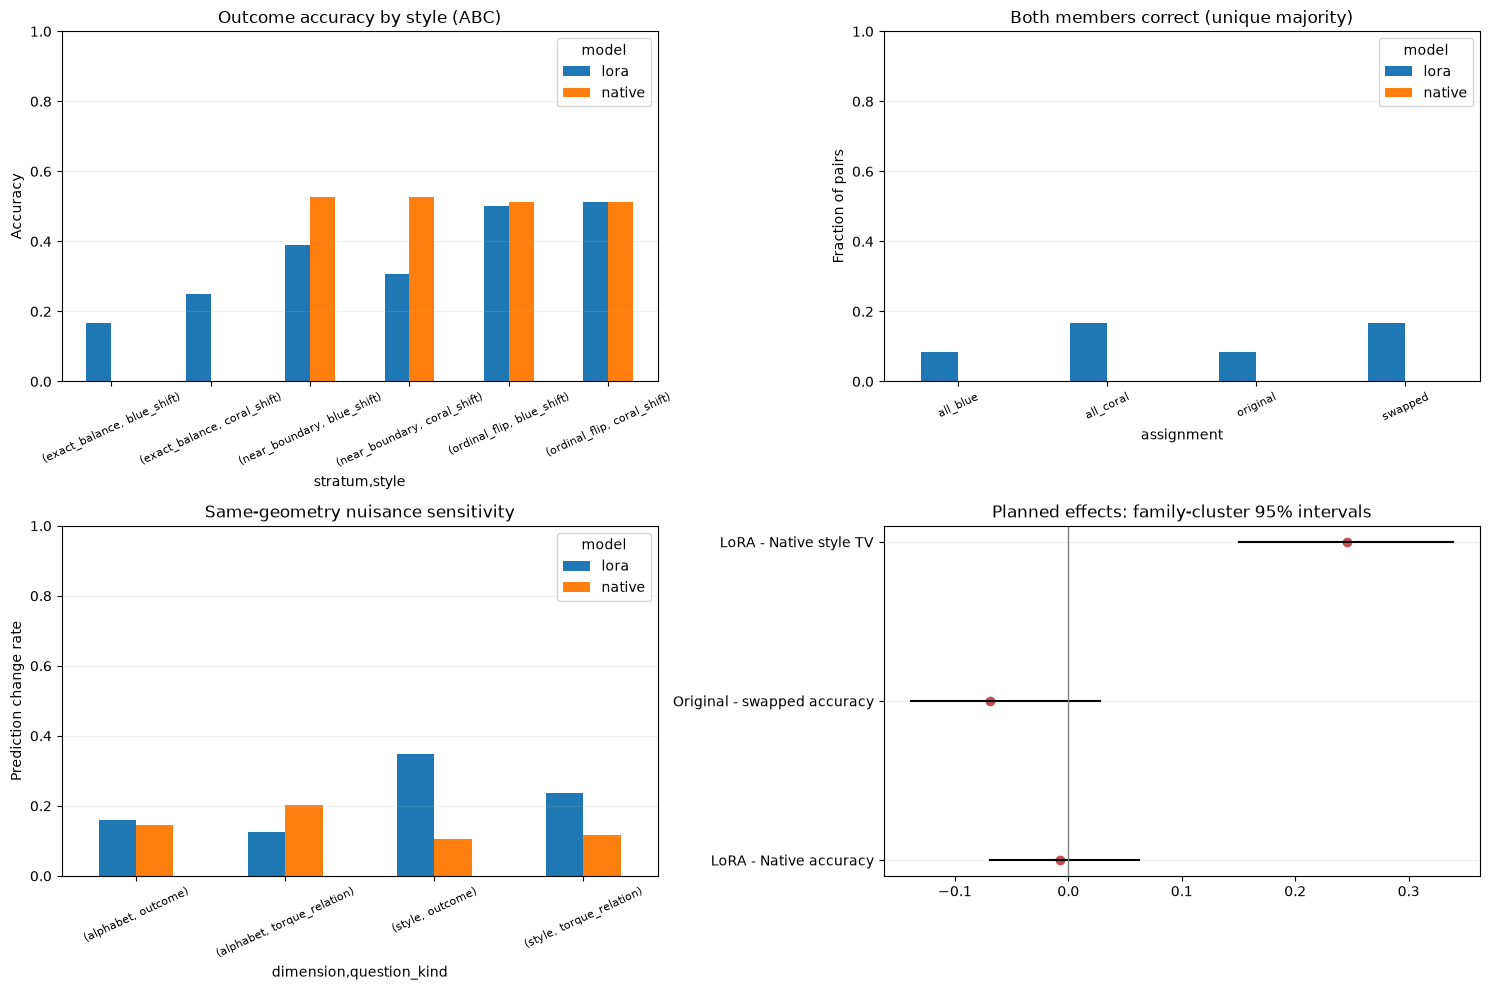

Audit completed: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_style_code_crossover_v1/RUN_COMPLETE.json
Read first: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_style_code_crossover_v1/FOLLOWUP_REPORT_ZH.md
Figure: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_style_code_crossover_v1/analysis/figures/style_code_crossover_summary.png
Technical status: passed


In [15]:
%%cell_progress 14/14 Save figures, the interpretation report and completion record
cell_stage('Rendering the controlled comparison')
figure,axes = plt.subplots(2,2,figsize=(15,10))
plot = scene_frame[(scene_frame['question_kind']=='outcome') & (scene_frame['alphabet']=='ABC')]
plot.groupby(['stratum','style','model'])['accuracy'].mean().unstack('model').plot.bar(ax=axes[0,0])
axes[0,0].set(title='Outcome accuracy by style (ABC)',ylim=(0,1),ylabel='Accuracy')
ps = pair_summary[(pair_summary['question_kind']=='outcome') & (pair_summary['alphabet']=='ABC')]
ps.pivot(index='assignment',columns='model',values='both_modal_correct').plot.bar(ax=axes[0,1])
axes[0,1].set(title='Both members correct (unique majority)',ylim=(0,1),ylabel='Fraction of pairs')
ns = sensitivity_scene[sensitivity_scene['stratum']=='ordinal_flip']
ns.groupby(['dimension','question_kind','model'])['prediction_change_rate'].mean().unstack('model').plot.bar(ax=axes[1,0])
axes[1,0].set(title='Same-geometry nuisance sensitivity',ylim=(0,1),ylabel='Prediction change rate')
for index,row in enumerate(planned):
    axes[1,1].plot([row['ci_low'],row['ci_high']],[index,index],color='black')
    axes[1,1].scatter([row['mean']],[index],color='#c44e52')
axes[1,1].axvline(0,color='gray',linewidth=1)
axes[1,1].set_yticks(range(3),['LoRA - Native accuracy','Original - swapped accuracy','LoRA - Native style TV'])
axes[1,1].set_title('Planned effects: family-cluster 95% intervals')
for ax in axes.flat:
    ax.grid(axis='y',alpha=.2)
for ax in (axes[0,0],axes[0,1],axes[1,0]): ax.tick_params(axis='x',rotation=25,labelsize=8)
figure.tight_layout()
FIGURE_PATH = FIGURE_DIR/'style_code_crossover_summary.png'
figure.savefig(FIGURE_PATH,dpi=180,bbox_inches='tight')
plt.show()

lines = ['# 画风 × 答案字母交叉复核结果','',
    '**性质：已看过场景的受控事后复核；不是新的盲测，也不证明力矩中介。**','',
    f"技术复现状态：{decision['technical_status']}；旧预测匹配率：{decision['prior_prediction_match_rate']:.2%}。",
    f"44 个物理场景，12 个配对；主分析只有 {len(primary_families)} 个独立连通 family。",'',
    '| 预先锁定的本轮对比 | 均值 | 95% 区间 | Holm p |','|---|---:|---|---:|']
names = ['交叉画风平均：LoRA−Native 准确率','LoRA：原风格分配−交换分配准确率','LoRA−Native：换风格的语义概率变化 TV']
for name,row in zip(names,planned):
    lines.append(f"| {name} | {row['mean']:.4f} | [{row['ci_low']:.4f}, {row['ci_high']:.4f}] | {row['holm_p_value']:.4f} |")
lines += ['', '前两项乘 100 是百分点；第三项是概率总变差，范围 0–1。区间为逐项区间；三项 p 值使用 Holm 校正。', '',
    '## 如何读结果', '',
    '- 先看 technical_status；若旧输入的分数不能复现，先检查运行环境，不把差异归因于画风。',
    '- 对照 pair_summary.csv 的 original、swapped、all_blue、all_coral；关注 both_modal_correct 和 both_all_mappings_correct，而不只看翻转率。',
    '- 查看 style_and_alphabet_sensitivity.csv：同一物理场景换画风/字母是否改变语义预测。稳定但错误也会保持不变。',
    '- 查看 behavior_summary.csv 的 balanced_prediction_rate、weight_follow_rate、distance_follow_rate 和 modal_tie_rate，排查捷径替换与平票。',
    '- task × alphabet 交互为探索性诊断；XYZ 效果变化不能单独说明 torque_relation 机制变化。',
    '- 若画风交换显著影响结果，先使用与物理标签独立的统一/交叉渲染重新建立行为证据；本实验不能进一步区分颜色、尺寸和布局。',
    '- 若画风控制后收益仍存在，再做同一渲染协议下的距离范围比较，并在冻结 L50/rank-4 的新保留场景上检查双向干预。',
    '- 若收益仍未确认，报告当前分布下的泛化边界；不因 p>0.05 宣称没有影响，也不增加搜索直到显著。',
    '', '## 证据边界', '',
    '本轮不训练、不选择子空间、不证明连续或精确净力矩运算。两个任务有相同物理三分类目标；共享效果不等于顺序计算链。',
    'family 同时连接镜像和配对；不同图像、排列、任务和字母不增加独立物理样本数。']
REPORT_PATH = OUTPUT_ROOT/'FOLLOWUP_REPORT_ZH.md'
REPORT_PATH.write_text('\n'.join(lines)+'\n',encoding='utf-8')

cell_stage('Verifying completeness and immutable inputs')
expected_paths = {prediction_path(ex,mode) for mode in MODES for ex in test_examples}
actual_paths = {path for path in PREDICTION_DIR.glob('*.json') if path.name!='identity.json'}
assert actual_paths == expected_paths and len(actual_paths)==2112
for key,path in SOURCE_PATHS.items(): assert sha256_file(path) == protocol['source_hashes'][key]
for sid,record in prior_scene_by_id.items(): assert sha256_file(PRIOR_DATASET/record['image_path']) == source_image_hashes[sid]
assert hash_tree(ADAPTER_DIR) == adapter_manifest['adapter_files']
for name,expected in data_identity['dataset_hashes'].items(): assert sha256_file(DATASET_DIR/name)==expected
for name,expected in data_identity['image_hashes'].items(): assert sha256_file(DATASET_DIR/name)==expected
assert sha256_file(OUTPUT_ROOT/'crossed_prompt_manifest.jsonl')==data_identity['manifest_sha256']
assert sha256_file(OUTPUT_ROOT/'crossed_scene_manifest.jsonl')==data_identity['scene_manifest_sha256']
required_outputs = [ANALYSIS_DIR/name for name in (
    'all_prompt_predictions.jsonl','scene_behavior.csv','pair_behavior.csv','pair_summary.csv',
    'behavior_summary.csv','style_and_alphabet_sensitivity.csv','planned_contrasts.csv',
    'descriptive_intervals.csv','prior_prediction_parity.csv','audit_decision.json',
    'exploratory_task_alphabet_interactions.csv','candidate_scoring_parity.json')]
required_outputs += [PROTOCOL_PATH,DATA_LOCK_PATH,REPORT_PATH,FIGURE_PATH]
assert all(path.is_file() and path.stat().st_size>0 for path in required_outputs)
write_json(OUTPUT_ROOT/'RUN_COMPLETE.json',{
    'run_id':RUN_ID,'completed_at_utc':datetime.now(timezone.utc).isoformat(),
    'input_count':1056,'score_count':2112,'technical_status':decision['technical_status'],
    'scientific_status':'controlled_diagnostic_completed_not_mechanism_confirmation',
    'artifact_hashes':{path.relative_to(OUTPUT_ROOT).as_posix():sha256_file(path) for path in required_outputs}})
print('Audit completed:',OUTPUT_ROOT/'RUN_COMPLETE.json')
print('Read first:',REPORT_PATH)
print('Figure:',FIGURE_PATH)
print('Technical status:',decision['technical_status'])
